Question 72. Plot Spending Score density for Purchase Yes/No, across regions.

Original dataset:


,ID,Age,Income,Spending Score,Region,Category,Visits,Online Time,Purchase,Rating
0,1,22,25000,65,North,Grocery,5,12,Yes,4.2
1,2,35,55000,40,West,Electronics,2,8,No,3.8
2,3,28,32000,70,South,Clothing,6,15,Yes,4.5
3,4,45,75000,30,East,Grocery,3,6,No,3.5
4,5,30,60000,80,South,Electronics,7,18,Yes,4.8
5,6,26,40000,55,North,Clothing,4,10,Yes,4.1
6,7,38,50000,45,West,Grocery,3,9,No,3.9
7,8,29,45000,75,South,Electronics,6,16,Yes,4.6
8,9,50,80000,35,West,Clothing,2,5,No,3.6
9,10,33,52000,60,North,Grocery,5,11,Yes,4.3


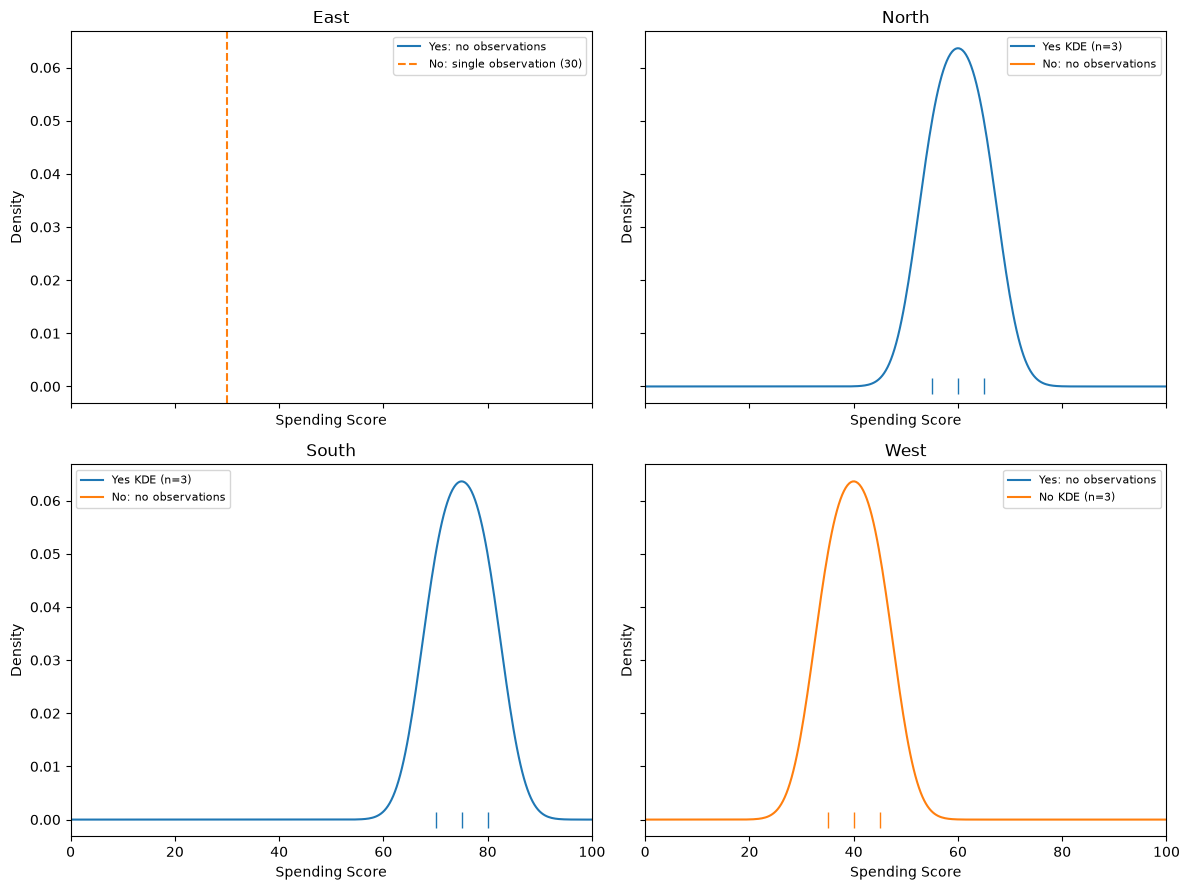

Saved question72_plot.png


In [1]:
# Step 1: Import the libraries needed for this program.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# Step 2: Load the CSV file from this question's folder into a DataFrame (table).
df = pd.read_csv("Customer_PurchaseData.csv")
print("Original dataset:")
display(df)

# Step 3: Create one panel for each region and a common Spending Score grid.
regions = sorted(df["Region"].unique())
fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)
x_grid = np.linspace(0, 100, 300)

# Step 4: Collect the number of customers in each region and purchase class.
summary = []

# Step 5: Draw separate Yes/No densities where possible; explicitly label missing or single-value groups.
for ax, region in zip(axes.flat, regions):
    for purchase, colour in [("Yes", "tab:blue"), ("No", "tab:orange")]:
        values = df.loc[(df["Region"] == region) & (df["Purchase"] == purchase), "Spending Score"]
        summary.append({"Region": region, "Purchase": purchase, "Count": len(values)})
        if len(values) >= 2 and values.nunique() > 1:
            ax.plot(x_grid, gaussian_kde(values)(x_grid), color=colour,
                    label=f"{purchase} KDE (n={len(values)})")
            ax.plot(values, np.zeros(len(values)), "|", color=colour, markersize=12)
        elif len(values) == 1:
            ax.axvline(values.iloc[0], color=colour, linestyle="--",
                       label=f"{purchase}: single observation ({values.iloc[0]})")
        elif len(values) == 0:
            ax.plot([], [], color=colour, label=f"{purchase}: no observations")
        else:
            ax.axvline(values.iloc[0], color=colour, linestyle="--",
                       label=f"{purchase}: constant observations (KDE undefined)")
    ax.set(title=region, xlabel="Spending Score", ylabel="Density", xlim=(0, 100))
    ax.legend(fontsize=8)

# Step 6: Save group counts so the small sample sizes remain visible.
pd.DataFrame(summary).to_csv("region_purchase_counts.csv", index=False)

# Final step: Arrange labels, save the chart and display it below this cell.
fig.tight_layout()
fig.savefig("question72_plot.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved question72_plot.png")


Interpretation / method

No region contains both purchase classes: North/South are all Yes, West/East all No. East has one observation, so its KDE cannot be estimated. A dashed observation marker is explicitly labelled instead of fabricating a density.